# Data Cleaning

**Definisi**:

Data cleaning adalah proses mengidentifikasi dan mengatasi masalah kualitas dalam suatu kumpulan data sebelum dilakukan analisis. Data mentah yang berasal dari sumber dunia nyata hampir selalu mengandung kesalahan, nilai yang hilang, duplikat, dan ketidakkonsistenan. Pembersihan yang menyeluruh memastikan bahwa hasil analisis mencerminkan kenyataan, bukan sekadar artefak dari proses pengumpulan data.

**To do**:

Yang akan saya lakukan di proses data cleaning yaitu seperti memeriksa data kosong, duplikat, dan konsistensi.

**Alur kerja di notebook ini** (berlaku untuk setiap dataset):

1. Snapshot kondisi awal (bentuk data, data kosong, duplikat)
2. Membuang baris yang benar-benar kosong
3. Memperbaiki tipe data
4. Memeriksa validitas nilai (rentang dan aturan logis)
5. Menangani data kosong (missing value)
6. Memeriksa duplikat
7. Memeriksa outlier
8. Membuat fitur turunan yang dibutuhkan analisis
9. Menyimpan hasil bersih ke `datasets/clean/` dan mencatat setiap keputusan di *cleaning log*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
datasets_dir = "../datasets/raw/"

### Persiapan: fungsi bantu dan cleaning log

Cell di bawah menyiapkan tiga hal:

- `clean_dir`: folder tujuan hasil bersih (`../datasets/clean/`).
- `log_step()`: mencatat setiap keputusan cleaning (isu, keputusan, alasan, jumlah baris terdampak). Hasilnya ditampilkan dan disimpan di akhir notebook sebagai `cleaning_log.csv`.
- `read_table()`: membaca file `.csv`; jika tidak ada, otomatis membaca `Sheet1` dari file `.xlsx` dengan nama yang sama.
- `parse_dates()`: mengubah teks tanggal menjadi tipe tanggal. Format `M/D/YYYY` (hasil ekspor CSV Anda) dicoba lebih dulu, lalu `YYYY-MM-DD`. Jika dua-duanya gagal, notebook berhenti dengan pesan error, bukan menebak diam-diam.

In [3]:
import os

clean_dir = "../datasets/clean/"
os.makedirs(clean_dir, exist_ok=True)

cleaning_log = []

def log_step(dataset, isu, keputusan, alasan, baris_terdampak):
    cleaning_log.append({
        "dataset": dataset,
        "isu": isu,
        "keputusan": keputusan,
        "alasan": alasan,
        "baris_terdampak": baris_terdampak,
    })

def read_table(name):
    csv_path = datasets_dir + name + ".csv"
    xlsx_path = datasets_dir + name + ".xlsx"
    if os.path.exists(csv_path):
        return pd.read_csv(csv_path)
    if os.path.exists(xlsx_path):
        return pd.read_excel(xlsx_path, sheet_name="Sheet1")
    raise FileNotFoundError(f"Tidak ada {csv_path} maupun {xlsx_path}")

def parse_dates(series):
    for fmt in ("%m/%d/%Y", "%Y-%m-%d"):
        try:
            return pd.to_datetime(series, format=fmt)
        except (ValueError, TypeError):
            continue
    raise ValueError("Format tanggal tidak dikenali, cek kolom date")

## Data Cleaning

1. **df_mt:** Data frame mobile transaction
2. **df_wo:** Data frame wifi offers
3. **df_ul:** Data frame usage logs
4. **df_si:** Data frame scenarios inputs

> **Perbaikan penting dari notebook sebelumnya.** Pada versi awal, keempat DataFrame (`df_mt`, `df_wo`, `df_ul`, `df_si`) semuanya membaca file `mobile_transactions.csv`, sehingga `df_wo`, `df_ul`, dan `df_si` isinya sama dengan `df_mt` (terlihat dari kolom `date`, `package_name`, `price`, dst. pada output `head()` Wifi Offers, Usage Logs, dan Scenario Inputs). Sekarang masing-masing membaca file yang benar.

In [4]:
df_mt = read_table("mobile_transactions")
df_wo = read_table("wifi_offers")
df_ul = read_table("usage_log")
df_si = read_table("scenario_inputs")

for nama, df in {"df_mt": df_mt, "df_wo": df_wo, "df_ul": df_ul, "df_si": df_si}.items():
    print(nama, df.shape, list(df.columns))

df_mt (37, 6) ['date', 'package_name', 'price', 'quota_gb', 'validity_days', 'extra_cost']
df_wo (53, 6) ['provider', 'package_name', 'monthly_cost', 'installation_cost', 'speed_mbps', 'contract_months']
df_ul (21, 5) ['date', 'data_used_gb', 'usage_hours', 'activity_type', 'connection_issue_count']
df_si (84, 7) ['scenario_id', 'users', 'months', 'mobile_cost', 'wifi_cost', 'installation_cost', 'extra_mobile_cost']


### Mobile Transaction

In [5]:
df_mt.head(10)

,date,package_name,price,quota_gb,validity_days,extra_cost
0,7/24/2025,FlexMini,25000.0,14.0,7.0,0.0
1,7/29/2025,FlexMini,25000.0,14.0,7.0,0.0
2,7/1/2026,FlexMini,17500.0,6.0,7.0,0.0
3,7/3/2026,Xtra Combo Mini,10000.0,1.5,3.0,0.0
4,7/5/2026,FlexMini,21500.0,10.0,7.0,0.0
5,7/8/2026,FlexMini,17500.0,6.0,7.0,0.0
6,7/11/2026,FlexMini,20000.0,8.0,7.0,0.0
7,7/14/2026,FlexMini,15000.0,4.0,7.0,0.0
8,7/16/2026,FlexMini,21500.0,10.0,7.0,0.0
9,7/20/2026,Xtra Combo Mini,10000.0,1.5,3.0,0.0


In [6]:
df_mt.info()

<class 'pandas.DataFrame'>
RangeIndex: 37 entries, 0 to 36
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           34 non-null     str    
 1   package_name   34 non-null     str    
 2   price          34 non-null     float64
 3   quota_gb       34 non-null     float64
 4   validity_days  34 non-null     float64
 5   extra_cost     34 non-null     float64
dtypes: float64(4), str(2)
memory usage: 1.9 KB


#### MT-1. Snapshot kondisi awal

Dari `info()` di atas terlihat `RangeIndex: 37 entries` tetapi `Non-Null Count` hanya 34. Artinya ada **3 baris yang seluruh kolomnya kosong**. Ini bukan data transaksi, melainkan sisa baris kosong dari ekspor Excel ke CSV.

In [7]:
print("Bentuk data:", df_mt.shape)
print("Baris yang seluruh kolomnya kosong:", int(df_mt.isna().all(axis=1).sum()))
print("\nJumlah data kosong per kolom:")
print(df_mt.isna().sum())
print("\nDuplikat persis (seluruh kolom sama):", int(df_mt.duplicated().sum()))

Bentuk data: (37, 6)
Baris yang seluruh kolomnya kosong: 3

Jumlah data kosong per kolom:
date             3
package_name     3
price            3
quota_gb         3
validity_days    3
extra_cost       3
dtype: int64

Duplikat persis (seluruh kolom sama): 2


#### MT-2. Membuang baris yang benar-benar kosong

Baris kosong tidak mengandung informasi, jadi aman dibuang. Dibuang hanya yang **seluruh** kolomnya kosong (`how="all"`), supaya baris dengan sebagian nilai kosong tidak ikut hilang tanpa sengaja.

In [8]:
n_kosong = int(df_mt.isna().all(axis=1).sum())
df_mt = df_mt.dropna(how="all").reset_index(drop=True)
log_step("mobile_transactions", "Baris kosong sisa ekspor CSV",
         "Dibuang (dropna how='all')",
         "Tidak ada informasi di baris tersebut", n_kosong)
print("Bentuk data setelah dibuang:", df_mt.shape)

Bentuk data setelah dibuang: (34, 6)


#### MT-3. Memperbaiki tipe data

- `date` terbaca sebagai teks (`str`) dengan format `M/D/YYYY`, sehingga harus diubah ke tipe tanggal agar bisa dikelompokkan per bulan.
- `price`, `validity_days`, dan `extra_cost` terbaca sebagai `float` hanya karena ada baris kosong tadi. Nilainya sebenarnya bilangan bulat, jadi diubah ke `Int64` (bilangan bulat yang tetap mengizinkan nilai kosong).
- Spasi di awal atau akhir nama paket dirapikan.

In [9]:
df_mt["date"] = parse_dates(df_mt["date"])
df_mt["package_name"] = df_mt["package_name"].str.strip()
df_mt["price"] = df_mt["price"].round().astype("Int64")
df_mt["validity_days"] = df_mt["validity_days"].round().astype("Int64")
df_mt["extra_cost"] = df_mt["extra_cost"].round().astype("Int64")
df_mt["quota_gb"] = df_mt["quota_gb"].astype(float)

print(df_mt.dtypes)
print("\nRentang tanggal:", df_mt["date"].min().date(), "sampai", df_mt["date"].max().date())
print("Nama paket unik:", df_mt["package_name"].unique().tolist())

date             datetime64[us]
package_name                str
price                     Int64
quota_gb                float64
validity_days             Int64
extra_cost                Int64
dtype: object

Rentang tanggal: 2025-07-24 sampai 2026-10-30
Nama paket unik: ['FlexMini', 'Xtra Combo Mini']


#### MT-4. Memeriksa validitas nilai

Aturan logis yang harus benar untuk data transaksi: harga, kuota, dan masa aktif harus positif; biaya tambahan tidak boleh negatif; dan tidak ada harga yang kosong. Hasil `True` berarti aman.

In [10]:
cek_mt = pd.Series({
    "price > 0 (semua baris)": bool((df_mt["price"] > 0).all()),
    "quota_gb > 0": bool((df_mt["quota_gb"] > 0).all()),
    "validity_days > 0": bool((df_mt["validity_days"] > 0).all()),
    "extra_cost >= 0": bool((df_mt["extra_cost"] >= 0).all()),
    "tidak ada price kosong": bool(df_mt["price"].notna().all()),
    "tanggal sudah berurutan": bool(df_mt["date"].is_monotonic_increasing),
})
print(cek_mt)
print("\nNilai unik extra_cost:", df_mt["extra_cost"].unique().tolist())

price > 0 (semua baris)    True
quota_gb > 0               True
validity_days > 0          True
extra_cost >= 0            True
tidak ada price kosong     True
tanggal sudah berurutan    True
dtype: bool

Nilai unik extra_cost: [0]


**Temuan:** `extra_cost` bernilai 0 di semua baris, jadi kolom ini konstan dan tidak membedakan transaksi satu dengan yang lain. Kolom tetap dipertahankan karena merupakan bagian dari skema dataset, tetapi tidak akan memengaruhi analisis. Hal ini dicatat di cleaning log.

In [11]:
log_step("mobile_transactions", "extra_cost bernilai 0 di semua baris (kolom konstan)",
         "Dipertahankan, dicatat sebagai keterbatasan",
         "Bagian dari skema dataset; tidak berpengaruh pada hitungan biaya", int(len(df_mt)))

#### MT-5. Menandai harga yang berupa estimasi

Sebanyak 15 harga pada data awal kosong, lalu diisi dengan **estimasi** (interpolasi dari harga paket sejenis di data Anda sendiri, bukan harga transaksi sebenarnya). Karena file CSV tidak membawa keterangan itu, penandanya direkonstruksi dari kombinasi (nama paket, kuota, masa aktif) yang memang tidak punya harga asli. Kombinasi ini diverifikasi cocok dengan sheet `catatan_data` pada file Excel.

Kolom baru `is_estimated` memungkinkan analisis dilakukan **dua kali**: hanya data asli, dan semua data. Selisih keduanya adalah ukuran ketidakpastian akibat estimasi.

> Jika nanti Anda mengganti harga estimasi dengan harga sebenarnya dari aplikasi operator, kosongkan atau perbarui daftar `ESTIMATED_COMBOS` di bawah.

In [12]:
ESTIMATED_COMBOS = {
    ("FlexMini", 4.0, 7), ("FlexMini", 6.0, 7), ("FlexMini", 10.0, 7), ("FlexMini", 5.0, 3),
    ("Xtra Combo Mini", 1.5, 3), ("Xtra Combo Mini", 2.0, 3),
}
df_mt["is_estimated"] = [
    (p, float(q), int(v)) in ESTIMATED_COMBOS
    for p, q, v in zip(df_mt["package_name"], df_mt["quota_gb"], df_mt["validity_days"])
]
print("Jumlah harga estimasi:", int(df_mt["is_estimated"].sum()), "dari", len(df_mt), "baris")
print(df_mt.groupby("is_estimated")["price"].agg(["count", "mean"]).rename(columns={"count": "n_baris", "mean": "rata2_harga"}))

log_step("mobile_transactions", "Harga kosong pada data awal sudah diisi estimasi",
         "Ditandai kolom is_estimated; tidak diimputasi ulang",
         "Estimasi bukan data asli, harus bisa dipisahkan saat analisis", int(df_mt["is_estimated"].sum()))

Jumlah harga estimasi: 15 dari 34 baris
              n_baris   rata2_harga
is_estimated                       
False              19  22947.368421
True               15  13633.333333


#### MT-6. Jendela waktu pengumpulan data

README menyebut periode pengumpulan data adalah **3 bulan terakhir (Agustus–Oktober 2026)**. Data Anda memuat tanggal di luar jendela itu (2 baris Juli 2025 dan beberapa baris Juli 2026).

**Keputusan:** baris di luar jendela **tidak dibuang**, hanya ditandai dengan kolom `in_window`. Alasannya, menghapus data tidak bisa dibatalkan, sedangkan penanda memungkinkan analisis memilih sendiri. Dua baris bertahun 2025 mungkin salah ketik tahun, jadi sebaiknya Anda cek ke aplikasi operator.

In [13]:
WINDOW_START, WINDOW_END = pd.Timestamp("2026-08-01"), pd.Timestamp("2026-10-31")
df_mt["in_window"] = df_mt["date"].between(WINDOW_START, WINDOW_END)
df_mt["month"] = df_mt["date"].dt.to_period("M").astype(str)

print(df_mt["in_window"].value_counts().rename({True: "di dalam jendela", False: "di luar jendela"}))
print("\nJumlah transaksi per bulan:")
print(df_mt["month"].value_counts().sort_index())
print("\nBaris di luar jendela pada tahun 2025:")
print(df_mt[df_mt["date"].dt.year == 2025][["date", "package_name", "price", "quota_gb"]])

log_step("mobile_transactions", "Tanggal di luar jendela Agustus–Oktober 2026 (termasuk 2 baris Juli 2025)",
         "Dipertahankan, ditandai in_window = False",
         "Penghapusan tidak bisa dibatalkan; analisis inti cukup memfilter in_window", int((~df_mt["in_window"]).sum()))

in_window
di dalam jendela    22
di luar jendela     12
Name: count, dtype: int64

Jumlah transaksi per bulan:
month
2025-07     2
2026-07    10
2026-08    10
2026-09     6
2026-10     6
Name: count, dtype: int64

Baris di luar jendela pada tahun 2025:
        date package_name  price  quota_gb
0 2025-07-24     FlexMini  25000      14.0
1 2025-07-29     FlexMini  25000      14.0


#### MT-7. Memeriksa duplikat

Pembelian paket yang sama pada hari yang sama bisa sah (misalnya membeli dua kali). Karena itu pengecekan dilakukan dua tingkat: duplikat **persis** (semua kolom sama), lalu **calon duplikat** (tanggal, paket, kuota, masa aktif sama).

In [14]:
dup_persis = df_mt.duplicated(subset=["date", "package_name", "price", "quota_gb", "validity_days", "extra_cost"], keep=False)
dup_calon = df_mt.duplicated(subset=["date", "package_name", "quota_gb", "validity_days"], keep=False)
print("Duplikat persis :", int(dup_persis.sum()), "baris")
print("Calon duplikat  :", int(dup_calon.sum()), "baris")
if dup_calon.any():
    print(df_mt[dup_calon][["date", "package_name", "price", "quota_gb", "validity_days"]])

log_step("mobile_transactions", "Pengecekan duplikat transaksi (tanggal+paket+kuota+masa aktif)",
         "Tidak ada baris dibuang" if not dup_calon.any() else "Ditinjau manual, tidak otomatis dibuang",
         "Tidak ditemukan duplikat" if not dup_calon.any() else "Pembelian ulang di hari yang sama bisa sah",
         int(dup_calon.sum()))

Duplikat persis : 0 baris
Calon duplikat  : 0 baris


#### MT-8. Fitur turunan dan pemeriksaan outlier

Fitur baru: `total_cost` (harga + biaya tambahan), `price_per_gb`, dan `price_per_day`. Setelah `price_per_gb` ada, outlier diperiksa dengan aturan **IQR** (nilai di luar Q1 − 1,5×IQR atau Q3 + 1,5×IQR dianggap mencurigakan).

Grafik di bawah menunjukkan harga terhadap kuota. Titik oranye adalah harga estimasi; bila estimasinya wajar, titik oranye akan berada sejalan dengan pola titik biru (harga asli).

Batas wajar price_per_gb: -1160 sampai 6696
Jumlah outlier: 0
Empty DataFrame
Columns: [date, package_name, quota_gb, price, price_per_gb, is_estimated]
Index: []


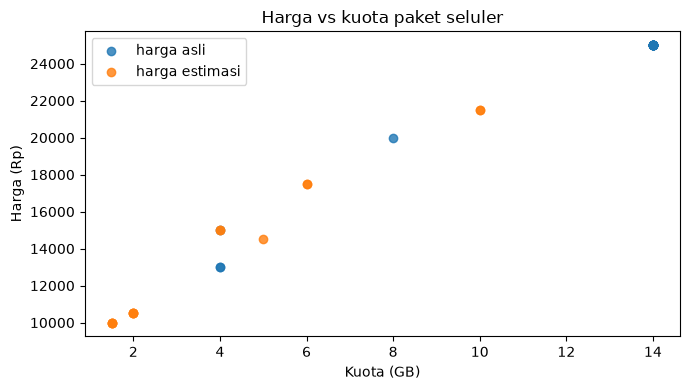

In [15]:
df_mt["total_cost"] = df_mt["price"] + df_mt["extra_cost"]
df_mt["price_per_gb"] = (df_mt["price"] / df_mt["quota_gb"]).round(0)
df_mt["price_per_day"] = (df_mt["price"] / df_mt["validity_days"]).round(0)

q1, q3 = df_mt["price_per_gb"].quantile([0.25, 0.75])
iqr = q3 - q1
batas_bawah, batas_atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out_mt = df_mt[(df_mt["price_per_gb"] < batas_bawah) | (df_mt["price_per_gb"] > batas_atas)]
print(f"Batas wajar price_per_gb: {batas_bawah:.0f} sampai {batas_atas:.0f}")
print("Jumlah outlier:", len(out_mt))
print(out_mt[["date", "package_name", "quota_gb", "price", "price_per_gb", "is_estimated"]])

fig, ax = plt.subplots(figsize=(7, 4))
for est, warna, label in [(False, "tab:blue", "harga asli"), (True, "tab:orange", "harga estimasi")]:
    sub = df_mt[df_mt["is_estimated"] == est]
    ax.scatter(sub["quota_gb"], sub["price"], c=warna, label=label, alpha=0.8)
ax.set_xlabel("Kuota (GB)"); ax.set_ylabel("Harga (Rp)")
ax.set_title("Harga vs kuota paket seluler")
ax.legend(); plt.tight_layout(); plt.show()

**Interpretasi:** pada data ini tidak ada nilai yang melewati batas IQR, jadi tidak ada baris yang perlu dibuang. Perlu dicatat bahwa paket **1,5 GB (harga estimasi)** berada sangat dekat dengan batas atas (sekitar Rp6.667 per GB). Paket berkuota kecil memang lebih mahal per GB, jadi itu pola struktural. Namun karena harga paket 1,5 GB adalah estimasi, angka ini yang paling perlu dicek ulang ke aplikasi operator.

In [16]:
log_step("mobile_transactions", "Outlier price_per_gb (IQR)",
         "Tidak ada tindakan" if len(out_mt) == 0 else "Dipertahankan",
         "Semua nilai dalam batas IQR (paket 1,5 GB estimasi mendekati batas atas)" if len(out_mt) == 0
         else "Paket kuota kecil memang lebih mahal per GB (struktural, bukan kesalahan input)",
         int(len(out_mt)))

#### MT-9. Ringkasan biaya bulanan (menjawab pertanyaan analisis 1)

Tabel ini menghitung total pembelian per bulan beserta jumlah harga estimasinya. Rata-rata bulanan dihitung dua cara:

- **Hanya bulan yang seluruh harganya asli** (tanpa estimasi), yaitu angka yang paling bisa dipercaya.
- **Seluruh bulan dalam jendela** (Agustus–Oktober), yang sebagian harganya estimasi.

Selisih keduanya menunjukkan seberapa besar estimasi memengaruhi kesimpulan.

In [17]:
monthly = (df_mt.groupby("month")
           .agg(n_transaksi=("price", "size"),
                total_biaya=("total_cost", "sum"),
                kuota_total_gb=("quota_gb", "sum"),
                n_estimasi=("is_estimated", "sum"))
           .reset_index())
monthly["status"] = np.where(monthly["n_estimasi"] == 0, "semua harga asli", "mengandung estimasi")
display(monthly)

bulan_jendela = ["2026-08", "2026-09", "2026-10"]
rata_semua = monthly[monthly["month"].isin(bulan_jendela)]["total_biaya"].astype(float).mean()
rata_asli = monthly[monthly["month"].isin(bulan_jendela) & (monthly["n_estimasi"] == 0)]["total_biaya"].astype(float).mean()
print(f"Rata-rata per bulan, hanya bulan berharga asli : Rp{rata_asli:,.0f}")
print(f"Rata-rata per bulan, Agustus-Oktober (semua)   : Rp{rata_semua:,.0f}")
print(f"Selisih akibat estimasi                         : Rp{rata_semua - rata_asli:,.0f}")

,month,n_transaksi,total_biaya,kuota_total_gb,n_estimasi,status
0,2025-07,2,50000,28.0,0,semua harga asli
1,2026-07,10,153000,50.0,9,mengandung estimasi
2,2026-08,10,171500,73.0,6,mengandung estimasi
3,2026-09,6,126000,64.0,0,semua harga asli
4,2026-10,6,140000,74.0,0,semua harga asli


Rata-rata per bulan, hanya bulan berharga asli : Rp133,000
Rata-rata per bulan, Agustus-Oktober (semua)   : Rp145,833
Selisih akibat estimasi                         : Rp12,833


#### MT-10. Menyimpan hasil bersih

In [18]:
kolom_mt = ["date", "month", "package_name", "price", "quota_gb", "validity_days", "extra_cost",
            "total_cost", "price_per_gb", "price_per_day", "is_estimated", "in_window"]
df_mt_clean = df_mt[kolom_mt].copy()
df_mt_clean.to_csv(clean_dir + "mobile_transactions_clean.csv", index=False, date_format="%Y-%m-%d")
print("Tersimpan:", df_mt_clean.shape)
df_mt_clean.head()

Tersimpan: (34, 12)


,date,month,package_name,price,quota_gb,validity_days,extra_cost,total_cost,price_per_gb,price_per_day,is_estimated,in_window
0,2025-07-24,2025-07,FlexMini,25000,14.0,7,0,25000,1786.0,3571.0,False,False
1,2025-07-29,2025-07,FlexMini,25000,14.0,7,0,25000,1786.0,3571.0,False,False
2,2026-07-01,2026-07,FlexMini,17500,6.0,7,0,17500,2917.0,2500.0,True,False
3,2026-07-03,2026-07,Xtra Combo Mini,10000,1.5,3,0,10000,6667.0,3333.0,True,False
4,2026-07-05,2026-07,FlexMini,21500,10.0,7,0,21500,2150.0,3071.0,True,False


### Wifi Offers

Menampilkan 10 data pertama dan melihat infromasi summary dari dataframe Wifi Offers.

In [19]:
df_wo.head(10)

,provider,package_name,monthly_cost,installation_cost,speed_mbps,contract_months
0,IndiHome,Paket JITU 1 1P 30 Mbps 295K,295000,0.0,30,12.0
1,IndiHome,Paket Complete 1P 100 Mbps,515000,0.0,100,12.0
2,IndiHome,Paket JITU 1 2P-TV 30 Mbps 340K,340000,250000.0,30,12.0
3,IndiHome,Paket JITU 1 2P-TV 30 Mbps 455K,455000,250000.0,30,12.0
4,IndiHome,Paket JITU 1 3P 30 Mbps 360K,360000,250000.0,30,12.0
5,EZnet by Telkomsel,EZnet Wireless 10 Mbps,150000,150000.0,10,12.0
6,Biznet Home,Home 0D 50 Mbps,250000,250000.0,50,0.0
7,Biznet Home,Home 1D 150 Mbps,375000,250000.0,150,0.0
8,Biznet Home,Home 2D 250 Mbps,575000,250000.0,250,0.0
9,Biznet Home,Gamers 3D 300 Mbps,700000,250000.0,300,0.0


In [20]:
df_wo.info()

<class 'pandas.DataFrame'>
RangeIndex: 53 entries, 0 to 52
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   provider           53 non-null     str    
 1   package_name       53 non-null     str    
 2   monthly_cost       53 non-null     int64  
 3   installation_cost  50 non-null     float64
 4   speed_mbps         53 non-null     int64  
 5   contract_months    46 non-null     float64
dtypes: float64(2), int64(2), str(2)
memory usage: 2.6 KB


#### WO-1. Snapshot kondisi awal

Kolom `installation_cost` dan `contract_months` punya data kosong. Ini bukan kesalahan input: informasinya memang tidak tersedia dari sumber (beberapa provider tidak mencantumkan biaya pasang atau kontrak di halaman yang diakses).

In [21]:
print("Bentuk data:", df_wo.shape)
print("Baris yang seluruh kolomnya kosong:", int(df_wo.isna().all(axis=1).sum()))
print("\nJumlah data kosong per kolom:")
print(df_wo.isna().sum())
print("\nDuplikat persis:", int(df_wo.duplicated().sum()))

Bentuk data: (53, 6)
Baris yang seluruh kolomnya kosong: 0

Jumlah data kosong per kolom:
provider             0
package_name         0
monthly_cost         0
installation_cost    3
speed_mbps           0
contract_months      7
dtype: int64

Duplikat persis: 0


#### WO-2. Membuang baris kosong dan memperbaiki tipe data

- Baris yang seluruh kolomnya kosong dibuang (jika ada).
- Spasi di awal/akhir teks dirapikan.
- `contract_months` diubah ke `Int64` supaya tetap bilangan bulat namun mengizinkan nilai kosong.
- Nama provider diperiksa agar tidak ada penulisan ganda untuk provider yang sama (misalnya `IndiHome` dan `Indihome`).

In [22]:
n_kosong_wo = int(df_wo.isna().all(axis=1).sum())
df_wo = df_wo.dropna(how="all").reset_index(drop=True)
log_step("wifi_offers", "Baris kosong", "Dibuang (dropna how='all')", "Tidak ada informasi", n_kosong_wo)

df_wo["provider"] = df_wo["provider"].str.strip()
df_wo["package_name"] = df_wo["package_name"].str.strip()
for kol in ["monthly_cost", "installation_cost", "contract_months"]:
    df_wo[kol] = df_wo[kol].round().astype("Int64")
df_wo["speed_mbps"] = df_wo["speed_mbps"].astype(float)

print(df_wo.dtypes)
print("\nProvider unik dan jumlah paketnya:")
print(df_wo["provider"].value_counts())

provider                 str
package_name             str
monthly_cost           Int64
installation_cost      Int64
speed_mbps           float64
contract_months        Int64
dtype: object

Provider unik dan jumlah paketnya:
provider
IndiHome              32
Iconnet                9
Biznet Home            4
MNC Play               4
Gastra Networks        3
EZnet by Telkomsel     1
Name: count, dtype: int64


#### WO-3. Memeriksa validitas nilai

Biaya bulanan dan kecepatan harus positif. Biaya pasang tidak boleh negatif (0 sah artinya gratis). Kontrak minimum 0 artinya **tidak ada kontrak**, sedangkan kosong artinya **tidak diketahui**. Keduanya berbeda arti dan tidak boleh dicampur.

In [23]:
cek_wo = pd.Series({
    "monthly_cost > 0": bool((df_wo["monthly_cost"] > 0).all()),
    "speed_mbps > 0": bool((df_wo["speed_mbps"] > 0).all()),
    "installation_cost >= 0 (yang terisi)": bool((df_wo["installation_cost"].dropna() >= 0).all()),
    "contract_months >= 0 (yang terisi)": bool((df_wo["contract_months"].dropna() >= 0).all()),
})
print(cek_wo)
print("\nNilai contract_months yang muncul:", sorted(df_wo["contract_months"].dropna().unique().tolist()))
print("Nilai installation_cost yang muncul:", sorted(df_wo["installation_cost"].dropna().unique().tolist()))

monthly_cost > 0                        True
speed_mbps > 0                          True
installation_cost >= 0 (yang terisi)    True
contract_months >= 0 (yang terisi)      True
dtype: bool

Nilai contract_months yang muncul: [0, 12]
Nilai installation_cost yang muncul: [0, 150000, 200000, 250000, 500000]


#### WO-4. Menangani data kosong

**Keputusan: data kosong tidak diimputasi.** Biaya pasang dan kontrak adalah fakta tertentu dari tiap provider yang tidak bisa ditebak dari kolom lain; mengisinya dengan rata-rata akan menghasilkan angka yang terlihat nyata padahal rekayasa. Sebagai gantinya dibuat kolom `info_lengkap` (True jika kedua kolom terisi), sehingga analisis titik impas bisa memakai hanya baris yang lengkap.

In [24]:
df_wo["info_lengkap"] = df_wo["installation_cost"].notna() & df_wo["contract_months"].notna()

kosong_per_provider = (df_wo.groupby("provider")
                       .agg(n_paket=("package_name", "size"),
                            installation_kosong=("installation_cost", lambda s: int(s.isna().sum())),
                            contract_kosong=("contract_months", lambda s: int(s.isna().sum())))
                       .reset_index())
display(kosong_per_provider)
print("Baris dengan informasi lengkap:", int(df_wo["info_lengkap"].sum()), "dari", len(df_wo))

log_step("wifi_offers", "installation_cost / contract_months kosong",
         "Tidak diimputasi; ditandai info_lengkap = False",
         "Fakta spesifik provider, tidak dapat ditebak dari kolom lain", int((~df_wo["info_lengkap"]).sum()))

,provider,n_paket,installation_kosong,contract_kosong
0,Biznet Home,4,0,0
1,EZnet by Telkomsel,1,0,0
2,Gastra Networks,3,3,3
3,Iconnet,9,0,0
4,IndiHome,32,0,0
5,MNC Play,4,0,4


Baris dengan informasi lengkap: 46 dari 53


#### WO-5. Memeriksa duplikat

Nama paket seperti `Paket IndiHome Netflix 2P-TV…` muncul berkali-kali karena **nama terpotong** pada tampilan sumber. Jadi duplikat tidak boleh dinilai dari nama saja. Pengecekan yang benar adalah duplikat pada semua kolom, dan pada kombinasi (provider, harga, kecepatan).

In [25]:
dup_wo_persis = int(df_wo.duplicated().sum())
dup_wo_nama = df_wo[df_wo.duplicated(subset=["provider", "package_name"], keep=False)].sort_values(["provider", "package_name"])
dup_wo_harga = int(df_wo.duplicated(subset=["provider", "monthly_cost", "speed_mbps"], keep=False).sum())

print("Duplikat persis (semua kolom)        :", dup_wo_persis)
print("Duplikat (provider+harga+kecepatan)  :", dup_wo_harga)
print("Nama paket kembar (nama terpotong)   :", len(dup_wo_nama), "baris")
display(dup_wo_nama[["provider", "package_name", "monthly_cost", "speed_mbps"]])

log_step("wifi_offers", "Nama paket kembar akibat nama terpotong di sumber",
         "Dipertahankan; baris dibedakan oleh harga dan kecepatan",
         "Harga/kecepatan berbeda, jadi penawarannya memang berbeda", int(len(dup_wo_nama)))

Duplikat persis (semua kolom)        : 0
Duplikat (provider+harga+kecepatan)  : 0
Nama paket kembar (nama terpotong)   : 9 baris


,provider,package_name,monthly_cost,speed_mbps
26,IndiHome,Paket IndiHome Gamer 2P-…,545000,50.0
27,IndiHome,Paket IndiHome Gamer 2P-…,375000,30.0
28,IndiHome,Paket IndiHome Gamer 2P-…,895000,100.0
11,IndiHome,Paket IndiHome Netflix 2P-TV…,385000,30.0
12,IndiHome,Paket IndiHome Netflix 2P-TV…,460000,50.0
14,IndiHome,Paket IndiHome Netflix 2P-TV…,365000,30.0
21,IndiHome,Paket IndiHome Netflix 2P-TV…,555000,100.0
13,IndiHome,Paket IndiHome Netflix 3P 30…,410000,30.0
19,IndiHome,Paket IndiHome Netflix 3P 30…,430000,30.0


#### WO-6. Fitur turunan: tipe paket, wilayah, dan biaya per Mbps

- `package_type`: paket **bundle** (internet + TV/telepon/Netflix) tidak sebanding langsung dengan paket **internet saja**. Pengelompokan ini dibuat dari pola pada nama paket (heuristik): IndiHome dengan `2P`, `3P`, atau `Netflix` = bundle; `1P`, `Dynamic`, `Complete` = internet saja. MNC Play diberi `tidak_jelas` karena isi paketnya tidak terlihat dari data.
- `region`: Iconnet menjual harga berbeda per wilayah (Sumatera, Jawa & Bali, Indonesia). Bangkalan (Madura) berada di Jawa, jadi varian yang relevan adalah **Jawa & Bali**.
- `relevan_bangkalan`: False untuk varian wilayah lain. Ini penanda wilayah saja; ketersediaan layanan di Bangkalan untuk tiap provider belum diverifikasi.
- `cost_per_mbps`: biaya bulanan dibagi kecepatan, untuk membandingkan nilai per kecepatan.

In [26]:
import re

def get_package_type(row):
    nama = row["package_name"].lower()
    if row["provider"] == "IndiHome":
        return "bundle" if re.search(r"\b[23]p\b|netflix", nama) else "internet_only"
    if row["provider"] == "MNC Play":
        return "tidak_jelas"
    return "internet_only"

def get_region(row):
    if row["provider"] != "Iconnet":
        return "tidak_berlaku"
    nama = row["package_name"]
    if "Jawa & Bali" in nama:
        return "Jawa & Bali"
    if "Sumatera" in nama:
        return "Sumatera"
    return "Indonesia (cakupan tidak jelas)"

df_wo["package_type"] = df_wo.apply(get_package_type, axis=1)
df_wo["region"] = df_wo.apply(get_region, axis=1)
df_wo["relevan_bangkalan"] = df_wo["region"].isin(["tidak_berlaku", "Jawa & Bali"])
df_wo["cost_per_mbps"] = (df_wo["monthly_cost"] / df_wo["speed_mbps"]).round(0)

print(pd.crosstab(df_wo["provider"], df_wo["package_type"]))
print()
print(df_wo[df_wo["provider"] == "Iconnet"]["region"].value_counts())

package_type        bundle  internet_only  tidak_jelas
provider                                              
Biznet Home              0              4            0
EZnet by Telkomsel       0              1            0
Gastra Networks          0              3            0
Iconnet                  0              9            0
IndiHome                23              9            0
MNC Play                 0              0            4

region
Sumatera                           3
Jawa & Bali                        3
Indonesia (cakupan tidak jelas)    3
Name: count, dtype: int64


#### WO-7. Memeriksa outlier

Harga bulanan dan biaya per Mbps diperiksa dengan IQR. Paket kecepatan sangat tinggi atau paket bundle TV secara alami lebih mahal, jadi nilai ekstrem di sini perlu dibaca sebagai **mahal tetapi nyata**, bukan salah ketik.

**Satu yang perlu dicek:** `GOFAST 100 Mbps` (Gastra Networks) seharga Rp1.100.000 jauh di atas paket 100 Mbps lain (sekitar Rp425.000–Rp680.000). Bisa jadi itu produk kelas bisnis atau ada ketentuan berbeda. Harganya sesuai sumber, tetapi hati-hati saat membandingkannya dengan paket rumahan.

Outlier monthly_cost : 4 baris


,provider,package_name,monthly_cost,speed_mbps
24,IndiHome,Paket IndiHome Gamer 3P 100…,965000,100.0
28,IndiHome,Paket IndiHome Gamer 2P-…,895000,100.0
36,IndiHome,Paket Dynamic 1P 300 Mbps,888000,300.0
50,Gastra Networks,GOFAST 100 Mbps,1100000,100.0


Outlier cost_per_mbps: 0 baris


,provider,package_name,monthly_cost,speed_mbps,cost_per_mbps


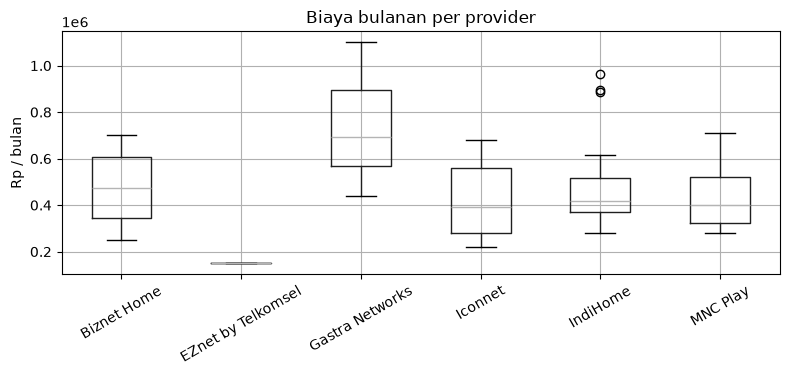

In [27]:
def iqr_outlier(df, kolom):
    q1, q3 = df[kolom].astype(float).quantile([0.25, 0.75])
    iqr = q3 - q1
    return df[(df[kolom].astype(float) < q1 - 1.5 * iqr) | (df[kolom].astype(float) > q3 + 1.5 * iqr)]

out_harga = iqr_outlier(df_wo, "monthly_cost")
out_mbps = iqr_outlier(df_wo, "cost_per_mbps")
print("Outlier monthly_cost :", len(out_harga), "baris")
display(out_harga[["provider", "package_name", "monthly_cost", "speed_mbps"]])
print("Outlier cost_per_mbps:", len(out_mbps), "baris")
display(out_mbps[["provider", "package_name", "monthly_cost", "speed_mbps", "cost_per_mbps"]])

fig, ax = plt.subplots(figsize=(8, 4))
df_wo.boxplot(column="monthly_cost", by="provider", ax=ax, rot=30)
ax.set_title("Biaya bulanan per provider"); plt.suptitle("")
ax.set_xlabel(""); ax.set_ylabel("Rp / bulan"); plt.tight_layout(); plt.show()

log_step("wifi_offers", "Outlier harga bulanan / biaya per Mbps (IQR)",
         "Dipertahankan",
         "Paket kecepatan tinggi atau bundle TV memang lebih mahal; harga sudah sesuai sumber",
         int(len(set(out_harga.index) | set(out_mbps.index))))

#### WO-8. Ringkasan per provider dan menyimpan hasil bersih

In [28]:
ringkasan_wo = (df_wo.groupby("provider")
                .agg(n_paket=("package_name", "size"),
                     harga_min=("monthly_cost", "min"),
                     harga_median=("monthly_cost", "median"),
                     harga_max=("monthly_cost", "max"),
                     kecepatan_min=("speed_mbps", "min"),
                     kecepatan_max=("speed_mbps", "max"))
                .reset_index())
display(ringkasan_wo)

kolom_wo = ["provider", "package_name", "monthly_cost", "installation_cost", "speed_mbps", "contract_months",
            "package_type", "region", "relevan_bangkalan", "cost_per_mbps", "info_lengkap"]
df_wo_clean = df_wo[kolom_wo].copy()
df_wo_clean.to_csv(clean_dir + "wifi_offers_clean.csv", index=False)
print("Tersimpan:", df_wo_clean.shape)

,provider,n_paket,harga_min,harga_median,harga_max,kecepatan_min,kecepatan_max
0,Biznet Home,4,250000,475000.0,700000,50.0,300.0
1,EZnet by Telkomsel,1,150000,150000.0,150000,10.0,10.0
2,Gastra Networks,3,440000,693000.0,1100000,25.0,100.0
3,Iconnet,9,220000,390000.0,680000,20.0,100.0
4,IndiHome,32,280000,417500.0,965000,30.0,300.0
5,MNC Play,4,279000,399000.0,709000,20.0,100.0


Tersimpan: (53, 11)


### Usage Logs

Menampilkan 10 data pertama dan melihat infromasi summary dari dataframe Usage Logs.

In [29]:
df_ul.head(10)

,date,data_used_gb,usage_hours,activity_type,connection_issue_count
0,2026-10-12,0.97,NaN,NaN,NaN
1,2026-10-13,1.60,NaN,NaN,NaN
2,2026-10-14,1.02,NaN,NaN,NaN
3,2026-10-15,1.57,NaN,NaN,NaN
4,2026-10-16,1.87,NaN,NaN,NaN
5,2026-10-17,3.34,NaN,NaN,NaN
6,2026-10-18,3.15,NaN,NaN,NaN
7,2026-10-19,2.90,NaN,NaN,NaN
8,2026-10-20,1.27,NaN,NaN,NaN
9,2026-10-21,0.95,NaN,NaN,NaN


In [30]:
df_ul.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   date                    21 non-null     str    
 1   data_used_gb            21 non-null     float64
 2   usage_hours             1 non-null      float64
 3   activity_type           1 non-null      str    
 4   connection_issue_count  0 non-null      float64
dtypes: float64(3), str(2)
memory usage: 972.0 bytes


#### UL-1. Snapshot kondisi awal

Hanya `data_used_gb` yang terisi lengkap. Tiga kolom lain (`usage_hours`, `activity_type`, `connection_issue_count`) hampir kosong karena datanya memang tidak tercatat oleh HP, bukan karena nilainya nol.

In [31]:
print("Bentuk data:", df_ul.shape)
print("Baris yang seluruh kolomnya kosong:", int(df_ul.isna().all(axis=1).sum()))
print("\nPersentase data kosong per kolom:")
print((df_ul.isna().mean() * 100).round(1).astype(str) + " %")
print("\nDuplikat persis:", int(df_ul.duplicated().sum()))

Bentuk data: (21, 5)
Baris yang seluruh kolomnya kosong: 0

Persentase data kosong per kolom:
date                        0.0 %
data_used_gb                0.0 %
usage_hours                95.2 %
activity_type              95.2 %
connection_issue_count    100.0 %
dtype: str

Duplikat persis: 0


#### UL-2. Membuang baris kosong dan memperbaiki tipe data

`date` diubah ke tipe tanggal, `connection_issue_count` ke `Int64` (bilangan bulat yang boleh kosong), dan `usage_hours` ke `float`.

In [32]:
n_kosong_ul = int(df_ul.isna().all(axis=1).sum())
df_ul = df_ul.dropna(how="all").reset_index(drop=True)
log_step("usage_log", "Baris kosong", "Dibuang (dropna how='all')", "Tidak ada informasi", n_kosong_ul)

df_ul["date"] = parse_dates(df_ul["date"])
df_ul["data_used_gb"] = df_ul["data_used_gb"].astype(float)
df_ul["usage_hours"] = df_ul["usage_hours"].astype(float)
df_ul["connection_issue_count"] = df_ul["connection_issue_count"].round().astype("Int64")
df_ul["activity_type"] = df_ul["activity_type"].astype("string").str.strip()
print(df_ul.dtypes)

date                      datetime64[us]
data_used_gb                     float64
usage_hours                      float64
activity_type                     string
connection_issue_count             Int64
dtype: object


#### UL-3. Memeriksa kelengkapan tanggal dan duplikat

Satu baris mewakili satu hari, jadi tanggal harus **berurutan tanpa celah** dan **tidak ada tanggal ganda**. Celah pada deret waktu bisa membuat rata-rata harian menyesatkan.

In [33]:
tanggal_lengkap = pd.date_range(df_ul["date"].min(), df_ul["date"].max(), freq="D")
tanggal_hilang = tanggal_lengkap.difference(df_ul["date"])
print("Periode:", df_ul["date"].min().date(), "sampai", df_ul["date"].max().date(), f"({len(tanggal_lengkap)} hari)")
print("Jumlah baris:", len(df_ul))
print("Tanggal yang hilang:", [d.date().isoformat() for d in tanggal_hilang] or "tidak ada")
print("Tanggal ganda:", int(df_ul["date"].duplicated().sum()))

log_step("usage_log", "Kelengkapan tanggal dan duplikat tanggal",
         "Tidak ada perbaikan diperlukan" if (len(tanggal_hilang) == 0 and not df_ul["date"].duplicated().any()) else "Perlu ditinjau",
         "Deret harian lengkap dan tidak ada tanggal ganda" if len(tanggal_hilang) == 0 else "Ada celah tanggal",
         int(len(tanggal_hilang) + df_ul["date"].duplicated().sum()))

Periode: 2026-10-12 sampai 2026-11-01 (21 hari)
Jumlah baris: 21
Tanggal yang hilang: tidak ada
Tanggal ganda: 0


#### UL-4. Memeriksa validitas nilai

In [34]:
cek_ul = pd.Series({
    "data_used_gb > 0": bool((df_ul["data_used_gb"] > 0).all()),
    "data_used_gb tidak kosong": bool(df_ul["data_used_gb"].notna().all()),
    "usage_hours antara 0 dan 24 (yang terisi)": bool(df_ul["usage_hours"].dropna().between(0, 24).all()),
    "connection_issue_count >= 0 (yang terisi)": bool((df_ul["connection_issue_count"].dropna() >= 0).all()),
})
print(cek_ul)
print(df_ul["data_used_gb"].describe().round(2))

data_used_gb > 0                             True
data_used_gb tidak kosong                    True
usage_hours antara 0 dan 24 (yang terisi)    True
connection_issue_count >= 0 (yang terisi)    True
dtype: bool
count    21.00
mean      1.85
std       0.78
min       0.74
25%       1.27
50%       1.67
75%       2.21
max       3.34
Name: data_used_gb, dtype: float64


#### UL-5. Menangani data kosong

**Keputusan: `usage_hours`, `activity_type`, dan `connection_issue_count` tidak diimputasi.** Dari 21 baris, hanya 1 baris (1 November) yang punya `usage_hours` dan `activity_type`, jadi tidak ada cukup data asli untuk membuat estimasi yang jujur. Ketiganya dipertahankan (sesuai skema README) dan dilaporkan sebagai keterbatasan. Analisis inti memakai `date` dan `data_used_gb`.

In [35]:
kosong_ul = df_ul[["usage_hours", "activity_type", "connection_issue_count"]].isna().sum()
print("Data kosong dari", len(df_ul), "baris:")
print(kosong_ul)

log_step("usage_log", "usage_hours, activity_type, connection_issue_count hampir kosong",
         "Tidak diimputasi; dipertahankan sesuai skema",
         "Tidak ada data asli yang cukup; imputasi akan mengarang data pribadi",
         int(kosong_ul.max()))

Data kosong dari 21 baris:
usage_hours               20
activity_type             20
connection_issue_count    21
dtype: int64


#### UL-6. Baris yang belum satu hari penuh, hari kerja/akhir pekan, dan outlier

- Baris **1 November** diambil pada malam hari (sekitar pukul 20.36), sehingga totalnya bisa lebih kecil dari satu hari penuh. Baris ini **ditandai** (`is_partial_day`), bukan dibuang.
- `day_type` (hari kerja atau akhir pekan) dibuat karena pola pemakaian bisa berbeda.
- Outlier `data_used_gb` diperiksa dengan IQR.

Batas wajar data_used_gb: -0.14 sampai 3.62 GB
Jumlah outlier: 0


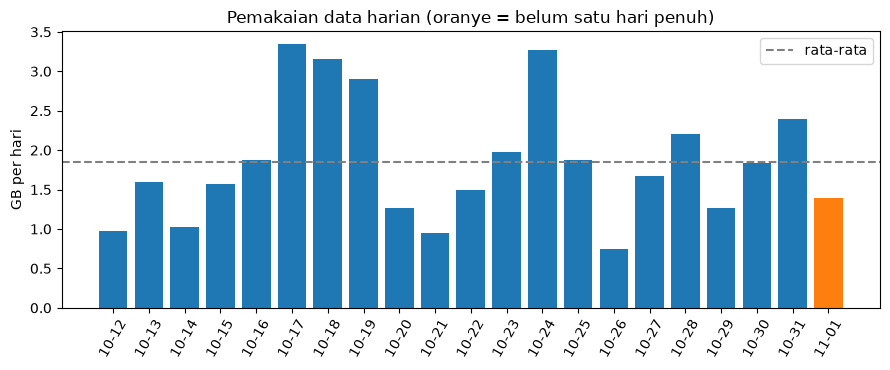

In [36]:
df_ul["is_partial_day"] = df_ul["date"] == df_ul["date"].max()
df_ul["day_type"] = np.where(df_ul["date"].dt.dayofweek >= 5, "akhir_pekan", "hari_kerja")

q1, q3 = df_ul["data_used_gb"].quantile([0.25, 0.75])
iqr = q3 - q1
out_ul = df_ul[(df_ul["data_used_gb"] < q1 - 1.5 * iqr) | (df_ul["data_used_gb"] > q3 + 1.5 * iqr)]
print(f"Batas wajar data_used_gb: {q1 - 1.5 * iqr:.2f} sampai {q3 + 1.5 * iqr:.2f} GB")
print("Jumlah outlier:", len(out_ul))

fig, ax = plt.subplots(figsize=(9, 3.8))
warna = np.where(df_ul["is_partial_day"], "tab:orange", "tab:blue")
ax.bar(df_ul["date"].dt.strftime("%m-%d"), df_ul["data_used_gb"], color=warna)
ax.axhline(df_ul["data_used_gb"].mean(), color="gray", linestyle="--", label="rata-rata")
ax.set_ylabel("GB per hari"); ax.set_title("Pemakaian data harian (oranye = belum satu hari penuh)")
plt.xticks(rotation=60); ax.legend(); plt.tight_layout(); plt.show()

log_step("usage_log", "Baris 1 November belum satu hari penuh",
         "Dipertahankan, ditandai is_partial_day = True",
         "Diambil malam hari; analisis dibandingkan dengan dan tanpa baris ini", int(df_ul["is_partial_day"].sum()))
log_step("usage_log", "Outlier data_used_gb (IQR)",
         "Tidak ada tindakan" if len(out_ul) == 0 else "Ditinjau, dipertahankan",
         "Semua nilai berada dalam batas IQR" if len(out_ul) == 0 else "Nilai tinggi masih wajar untuk pemakaian harian",
         int(len(out_ul)))

#### UL-7. Estimasi kebutuhan data bulanan

Rata-rata harian dikali 30 hari memberi perkiraan kebutuhan data per bulan. Dihitung dua cara untuk melihat pengaruh baris 1 November yang belum satu hari penuh. Angka ini dipakai nanti untuk menilai apakah kuota atau batas pemakaian wajar (FUP) paket cukup.

In [37]:
rata_semua_ul = df_ul["data_used_gb"].mean()
rata_penuh_ul = df_ul.loc[~df_ul["is_partial_day"], "data_used_gb"].mean()
print(f"Rata-rata harian, semua hari          : {rata_semua_ul:.2f} GB  -> sekitar {rata_semua_ul * 30:.0f} GB/bulan")
print(f"Rata-rata harian, tanpa hari parsial  : {rata_penuh_ul:.2f} GB  -> sekitar {rata_penuh_ul * 30:.0f} GB/bulan")
print("\nRata-rata per jenis hari:")
per_tipe = df_ul.groupby("day_type")["data_used_gb"].agg(["count", "mean"]).round(2)
print(per_tipe)
selisih = per_tipe.loc["akhir_pekan", "mean"] / per_tipe.loc["hari_kerja", "mean"] - 1
print(f"\nAkhir pekan sekitar {selisih:.0%} lebih besar daripada hari kerja (sampel kecil: {int(per_tipe.loc['akhir_pekan', 'count'])} hari akhir pekan).")

kolom_ul = ["date", "data_used_gb", "usage_hours", "activity_type", "connection_issue_count", "day_type", "is_partial_day"]
df_ul_clean = df_ul[kolom_ul].copy()
df_ul_clean.to_csv(clean_dir + "usage_log_clean.csv", index=False, date_format="%Y-%m-%d")
print("\nTersimpan:", df_ul_clean.shape)

Rata-rata harian, semua hari          : 1.85 GB  -> sekitar 55 GB/bulan
Rata-rata harian, tanpa hari parsial  : 1.87 GB  -> sekitar 56 GB/bulan

Rata-rata per jenis hari:
             count  mean
day_type                
akhir_pekan      6  2.57
hari_kerja      15  1.56

Akhir pekan sekitar 65% lebih besar daripada hari kerja (sampel kecil: 6 hari akhir pekan).

Tersimpan: (21, 7)


### Scenario Inputs

Menampilkan 10 data pertama dan melihat infromasi summary dari dataframe Scenario Inputs.

In [38]:
df_si.head(10)

,scenario_id,users,months,mobile_cost,wifi_cost,installation_cost,extra_mobile_cost
0,S001,1,3,133000,220000,250000,20000
1,S002,1,6,133000,220000,250000,20000
2,S003,1,12,133000,220000,250000,20000
3,S004,1,24,133000,220000,250000,20000
4,S005,2,3,133000,220000,250000,20000
5,S006,2,6,133000,220000,250000,20000
6,S007,2,12,133000,220000,250000,20000
7,S008,2,24,133000,220000,250000,20000
8,S009,3,3,133000,220000,250000,20000
9,S010,3,6,133000,220000,250000,20000


In [39]:
df_si.info()

<class 'pandas.DataFrame'>
RangeIndex: 84 entries, 0 to 83
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   scenario_id        84 non-null     str  
 1   users              84 non-null     int64
 2   months             84 non-null     int64
 3   mobile_cost        84 non-null     int64
 4   wifi_cost          84 non-null     int64
 5   installation_cost  84 non-null     int64
 6   extra_mobile_cost  84 non-null     int64
dtypes: int64(6), str(1)
memory usage: 4.7 KB


#### SI-1. Snapshot, tipe data, dan duplikat

File ini dibuat sendiri (bukan hasil pengumpulan), jadi masalahnya biasanya lebih sedikit. Tetap dicek: baris kosong, tipe data, ID unik, dan skenario kembar (kombinasi parameter yang sama dengan ID berbeda).

In [40]:
n_kosong_si = int(df_si.isna().all(axis=1).sum())
df_si = df_si.dropna(how="all").reset_index(drop=True)
log_step("scenario_inputs", "Baris kosong", "Dibuang (dropna how='all')", "Tidak ada informasi", n_kosong_si)

df_si["scenario_id"] = df_si["scenario_id"].astype(str).str.strip()
kolom_angka = ["users", "months", "mobile_cost", "wifi_cost", "installation_cost", "extra_mobile_cost"]
for kol in kolom_angka:
    df_si[kol] = df_si[kol].round().astype("Int64")

print("Bentuk data:", df_si.shape)
print("Data kosong:", int(df_si.isna().sum().sum()))
print("scenario_id unik:", df_si["scenario_id"].is_unique)
print("Format ID benar (S + 3 digit):", bool(df_si["scenario_id"].str.fullmatch(r"S\d{3}").all()))
param = ["users", "months", "mobile_cost", "wifi_cost", "installation_cost", "extra_mobile_cost"]
print("Skenario kembar (parameter sama):", int(df_si.duplicated(subset=param).sum()))

Bentuk data: (84, 7)
Data kosong: 0
scenario_id unik: True
Format ID benar (S + 3 digit): True
Skenario kembar (parameter sama): 0


#### SI-2. Memeriksa validitas dan logika

Selain nilai tidak negatif, ada aturan logika: `extra_mobile_cost` (seluler tambahan setelah memakai Wi-Fi) **tidak boleh lebih besar** dari `mobile_cost` (seluler penuh), karena pengguna tidak mungkin membayar seluler lebih mahal daripada tanpa Wi-Fi.

In [41]:
cek_si = pd.Series({
    "users >= 1": bool((df_si["users"] >= 1).all()),
    "months > 0": bool((df_si["months"] > 0).all()),
    "mobile_cost > 0": bool((df_si["mobile_cost"] > 0).all()),
    "wifi_cost > 0": bool((df_si["wifi_cost"] > 0).all()),
    "installation_cost >= 0": bool((df_si["installation_cost"] >= 0).all()),
    "extra_mobile_cost >= 0": bool((df_si["extra_mobile_cost"] >= 0).all()),
    "extra_mobile_cost <= mobile_cost": bool((df_si["extra_mobile_cost"] <= df_si["mobile_cost"]).all()),
})
print(cek_si)
display(df_si[param].describe().loc[["min", "max"]])

log_step("scenario_inputs", "Validitas dan logika parameter skenario",
         "Tidak ada perbaikan diperlukan" if cek_si.all() else "Perlu ditinjau",
         "Semua aturan terpenuhi" if cek_si.all() else "Ada aturan yang dilanggar", int((~cek_si).sum()))

users >= 1                          True
months > 0                          True
mobile_cost > 0                     True
wifi_cost > 0                       True
installation_cost >= 0              True
extra_mobile_cost >= 0              True
extra_mobile_cost <= mobile_cost    True
dtype: bool


,users,months,mobile_cost,wifi_cost,installation_cost,extra_mobile_cost
min,1.0,3.0,81000.0,220000.0,0.0,0.0
max,5.0,36.0,250000.0,560000.0,750000.0,133000.0


#### SI-3. Pengecekan konsistensi antar file

Skenario hanya bermakna jika angkanya **bisa dilacak ke data asli**:

1. `wifi_cost` + `installation_cost` di tiap skenario harus cocok dengan salah satu paket di `wifi_offers` (khusus Biznet, biaya pasang di skenario = instalasi Rp250.000 + modem wajib beli Rp500.000).
2. `mobile_cost` dasar harus sama dengan rata-rata biaya bulanan di `mobile_transactions`.
3. Kebutuhan data bulanan dari `usage_log` dibandingkan dengan kuota yang dibeli di `mobile_transactions`, sebagai uji kewajaran.

In [42]:
# 1. wifi_cost + installation_cost <-> wifi_offers
ref = df_wo[["provider", "package_name", "monthly_cost", "installation_cost"]].rename(columns={"installation_cost": "installation_wo"})
ref["installation_skenario"] = ref["installation_wo"] + np.where(ref["provider"] == "Biznet Home", 500000, 0)
pasangan = df_si[["wifi_cost", "installation_cost"]].drop_duplicates()
m = pasangan.merge(ref, left_on=["wifi_cost", "installation_cost"],
                   right_on=["monthly_cost", "installation_skenario"], how="left")
cocok = (m.groupby(["wifi_cost", "installation_cost"])
          .agg(n_paket_cocok=("provider", "count"), contoh_provider=("provider", "first"),
               contoh_paket=("package_name", "first")).reset_index())
display(cocok)
print("Semua pasangan wifi_cost/installation_cost bisa dilacak ke wifi_offers:", bool((cocok["n_paket_cocok"] > 0).all()))

,wifi_cost,installation_cost,n_paket_cocok,contoh_provider,contoh_paket
0,220000,250000,1,Iconnet,Iconnet20 Jawa & Bali
1,250000,750000,1,Biznet Home,Home 0D 50 Mbps
2,280000,500000,1,IndiHome,Paket JITU 1 1P 30 Mbps 280K
3,295000,0,1,IndiHome,Paket JITU 1 1P 30 Mbps 295K
4,330000,250000,1,Iconnet,Iconnet50 Jawa & Bali
5,350000,500000,1,IndiHome,Paket JITU 1 1P 50 Mbps
6,560000,250000,1,Iconnet,Iconnet100 Jawa & Bali


Semua pasangan wifi_cost/installation_cost bisa dilacak ke wifi_offers: True


In [43]:
# 2. mobile_cost dasar <-> mobile_transactions
mobile_dasar = df_si["mobile_cost"].mode().iloc[0]
print(f"mobile_cost paling sering di skenario  : Rp{mobile_dasar:,.0f}")
print(f"Rata-rata bulan berharga asli (MT-9)    : Rp{rata_asli:,.0f}")
print(f"Rata-rata Agustus-Oktober (MT-9)        : Rp{rata_semua:,.0f}")
print("Cocok dengan rata-rata bulan berharga asli:", abs(mobile_dasar - rata_asli) < 1000)
print("Nilai mobile_cost lain di skenario:", sorted(df_si["mobile_cost"].unique().tolist()))

mobile_cost paling sering di skenario  : Rp133,000
Rata-rata bulan berharga asli (MT-9)    : Rp133,000
Rata-rata Agustus-Oktober (MT-9)        : Rp145,833
Cocok dengan rata-rata bulan berharga asli: True
Nilai mobile_cost lain di skenario: [81000, 100000, 133000, 146000, 180000, 250000]


In [44]:
# 3. Kebutuhan data (usage_log) vs kuota yang dibeli (mobile_transactions)
kebutuhan_bulan = rata_semua_ul * 30
kuota = monthly[monthly["month"].isin(["2026-09", "2026-10"])][["month", "kuota_total_gb"]]
print(f"Kebutuhan data per bulan (dari usage_log): sekitar {kebutuhan_bulan:.0f} GB")
display(kuota)
if (kuota["kuota_total_gb"] >= kebutuhan_bulan).all():
    print("Kuota yang dibeli sedikit di atas kebutuhan: wajar dan konsisten antara mobile_transactions dan usage_log.")
else:
    print("Kuota yang dibeli lebih kecil dari kebutuhan: kemungkinan ada kuota/paket lain atau pemakaian lewat Wi-Fi yang tidak tercatat.")

log_step("scenario_inputs", "Pelacakan antar file (wifi_offers, mobile_transactions)",
         "Semua nilai bisa dilacak" if bool((cocok["n_paket_cocok"] > 0).all()) else "Ada nilai yang tidak terlacak",
         "Skenario harus bersumber dari data asli", int((cocok["n_paket_cocok"] == 0).sum()))

df_si_clean = df_si[["scenario_id"] + param].copy()
df_si_clean.to_csv(clean_dir + "scenario_inputs_clean.csv", index=False)
print("\nTersimpan:", df_si_clean.shape)

Kebutuhan data per bulan (dari usage_log): sekitar 55 GB


,month,kuota_total_gb
3,2026-09,64.0
4,2026-10,74.0


Kuota yang dibeli sedikit di atas kebutuhan: wajar dan konsisten antara mobile_transactions dan usage_log.

Tersimpan: (84, 7)


## Ringkasan Cleaning Log

Tabel berikut berisi seluruh keputusan cleaning (isu, keputusan, alasan, dan jumlah baris terdampak). Tabel ini juga disimpan sebagai `cleaning_log.csv` dan bisa langsung dipakai sebagai bahan bagian *Data cleaning* di README.

In [45]:
log_df = pd.DataFrame(cleaning_log)
log_df.to_csv(clean_dir + "cleaning_log.csv", index=False)
pd.set_option("display.max_colwidth", 80)
display(log_df)

,dataset,isu,keputusan,alasan,baris_terdampak
0,mobile_transactions,Baris kosong sisa ekspor CSV,Dibuang (dropna how='all'),Tidak ada informasi di baris tersebut,3
1,mobile_transactions,extra_cost bernilai 0 di semua baris (kolom konstan),"Dipertahankan, dicatat sebagai keterbatasan",Bagian dari skema dataset; tidak berpengaruh pada hitungan biaya,34
2,mobile_transactions,Harga kosong pada data awal sudah diisi estimasi,Ditandai kolom is_estimated; tidak diimputasi ulang,"Estimasi bukan data asli, harus bisa dipisahkan saat analisis",15
3,mobile_transactions,Tanggal di luar jendela Agustus–Oktober 2026 (termasuk 2 baris Juli 2025),"Dipertahankan, ditandai in_window = False",Penghapusan tidak bisa dibatalkan; analisis inti cukup memfilter in_window,12
4,mobile_transactions,Pengecekan duplikat transaksi (tanggal+paket+kuota+masa aktif),Tidak ada baris dibuang,Tidak ditemukan duplikat,0
5,mobile_transactions,Outlier price_per_gb (IQR),Tidak ada tindakan,"Semua nilai dalam batas IQR (paket 1,5 GB estimasi mendekati batas atas)",0
6,wifi_offers,Baris kosong,Dibuang (dropna how='all'),Tidak ada informasi,0
7,wifi_offers,installation_cost / contract_months kosong,Tidak diimputasi; ditandai info_lengkap = False,"Fakta spesifik provider, tidak dapat ditebak dari kolom lain",7
8,wifi_offers,Nama paket kembar akibat nama terpotong di sumber,Dipertahankan; baris dibedakan oleh harga dan kecepatan,"Harga/kecepatan berbeda, jadi penawarannya memang berbeda",9
9,wifi_offers,Outlier harga bulanan / biaya per Mbps (IQR),Dipertahankan,Paket kecepatan tinggi atau bundle TV memang lebih mahal; harga sudah sesuai...,4


## Perbandingan Sebelum dan Sesudah

In [46]:
ringkas = pd.DataFrame({
    "dataset": ["mobile_transactions", "wifi_offers", "usage_log", "scenario_inputs"],
    "baris_akhir": [len(df_mt_clean), len(df_wo_clean), len(df_ul_clean), len(df_si_clean)],
    "kolom_akhir": [df_mt_clean.shape[1], df_wo_clean.shape[1], df_ul_clean.shape[1], df_si_clean.shape[1]],
    "sel_kosong_tersisa": [int(df_mt_clean.isna().sum().sum()), int(df_wo_clean.isna().sum().sum()),
                           int(df_ul_clean.isna().sum().sum()), int(df_si_clean.isna().sum().sum())],
})
display(ringkas)

,dataset,baris_akhir,kolom_akhir,sel_kosong_tersisa
0,mobile_transactions,34,12,0
1,wifi_offers,53,11,10
2,usage_log,21,7,61
3,scenario_inputs,84,7,0


## Keterbatasan Data (untuk README)

1. **Harga estimasi di mobile_transactions.** 15 dari 34 harga adalah estimasi, bukan transaksi sebenarnya. Hasil rata-rata bulanan sebaiknya dilaporkan dua versi (data asli saja dan semua data).
2. **Jendela waktu.** Baris di luar Agustus–Oktober 2026 dipertahankan tetapi ditandai; dua baris Juli 2025 perlu dicek keasliannya.
3. **wifi_offers belum lengkap.** Biaya pasang/kontrak untuk beberapa provider kosong atau berasal dari sumber sekunder, dan biaya pasang IndiHome sebagian adalah tarif normal, bukan promo. Ketersediaan layanan di Bangkalan belum diverifikasi.
4. **usage_log.** Hanya `data_used_gb` yang lengkap; `usage_hours`, `activity_type`, dan `connection_issue_count` hampir kosong. Data juga berasal dari kuota seluler (bukan trafik Wi-Fi).
5. **scenario_inputs.** Sebagian nilai (`extra_mobile_cost` dan variasi `mobile_cost`) adalah angka ilustrasi, bukan hasil pengukuran.

**Langkah berikutnya:** Exploratory Data Analysis dan analisis biaya (titik impas) memakai file di `datasets/clean/`.